# 01 · Data exploration: UNSW-NB15

**Goal:** understand the data before modelling. What does a row mean, how balanced are the
classes, what do the key features mean in networking terms, and what traps are hiding in here?

Everything below uses the **official training split** unless it says otherwise.
We only peek at the test split for its size and class balance. No decisions are made from it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nids import config
from nids.data import load_split

pd.set_option("display.max_columns", 50)

# Chart styling: one blue for single series; blue = normal, orange = attack when split by label.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10,
})

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / name, dpi=150, bbox_inches="tight")

train = load_split("train")
test = load_split("test")
print(f"train: {train.shape}   test: {test.shape}")

train: (175341, 45)   test: (82332, 45)


## 1. What is one row?

Each row is one **flow**: a summary of a conversation between two endpoints, built by Argus/Zeek
from packet captures. Think of it like a NetFlow record on a Cisco router: no payload, just
counters and metadata. `s*` columns describe the **source → destination** direction, `d*` the reply.

In [2]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


In [3]:
print("dtypes:", train.dtypes.value_counts().to_dict())
print("missing values  train:", int(train.isna().sum().sum()), " test:", int(test.isna().sum().sum()))

dtypes: {dtype('int64'): 30, dtype('float64'): 11, <StringDtype(storage='python', na_value=nan)>: 4}
missing values  train: 0  test: 0


## 2. Class balance: attacks are the *majority*

Real networks are overwhelmingly normal traffic. This lab dataset is the opposite.
That matters for evaluation: a "model" that answers **attack** for every row already gets
an accuracy equal to the attack share. Any real model has to clearly beat that floor, which is
why we'll report precision, recall and F1 rather than accuracy alone.

In [4]:
balance = pd.DataFrame({
    "train": train[config.TARGET].value_counts(normalize=True),
    "test": test[config.TARGET].value_counts(normalize=True),
}).rename(index={0: "normal", 1: "attack"})
display((balance * 100).round(1).astype(str) + "%")

for name, df in [("train", train), ("test", test)]:
    print(f"'always attack' accuracy on {name}: {df[config.TARGET].mean():.1%}")

,train,test
label,,
attack,68.1%,55.1%
normal,31.9%,44.9%


'always attack' accuracy on train: 68.1%
'always attack' accuracy on test: 55.1%


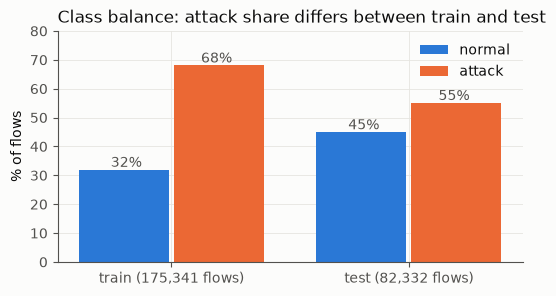

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
x = np.arange(2)
w = 0.38
ax.bar(x - w/2 - 0.01, balance.loc["normal"] * 100, w, color=BLUE, label="normal")
ax.bar(x + w/2 + 0.01, balance.loc["attack"] * 100, w, color=ORANGE, label="attack")
for i, split in enumerate(["train", "test"]):
    ax.text(i - w/2, balance.loc["normal", split] * 100 + 1, f"{balance.loc['normal', split]:.0%}", ha="center", color=MUTED)
    ax.text(i + w/2, balance.loc["attack", split] * 100 + 1, f"{balance.loc['attack', split]:.0%}", ha="center", color=MUTED)
ax.set_xticks(x, ["train (175,341 flows)", "test (82,332 flows)"])
ax.set_ylabel("% of flows")
ax.set_ylim(0, 80)
ax.set_title("Class balance: attack share differs between train and test", loc="left")
ax.legend(frameon=False)
save(fig, "01_class_balance.png")
plt.show()

The attack share **drops from ~68% in train to ~55% in test**. The two splits don't have the
same mix, so a model's decision threshold tuned for one won't be perfect on the other.
Keep that in mind when results come in.

## 3. Attack categories

Nine attack families plus Normal. `attack_cat` is what Phase 7 predicts. For Phases 3–6 it must be
**dropped**: it *is* the label in disguise (`attack_cat == "Normal"` ⇔ `label == 0`).

In [6]:
cats = train[config.ATTACK_CAT].value_counts()
cat_table = pd.DataFrame({"train": cats, "test": test[config.ATTACK_CAT].value_counts()})
cat_table["train %"] = (cat_table["train"] / len(train) * 100).round(2)
display(cat_table)

# Proof that attack_cat leaks the label
print("attack_cat == 'Normal' matches label == 0 on every row:",
      ((train[config.ATTACK_CAT] == "Normal") == (train[config.TARGET] == 0)).all())

,train,test,train %
attack_cat,,,
Normal,56000,37000,31.94
Generic,40000,18871,22.81
Exploits,33393,11132,19.04
Fuzzers,18184,6062,10.37
DoS,12264,4089,6.99
Reconnaissance,10491,3496,5.98
Analysis,2000,677,1.14
Backdoor,1746,583,1.00
Shellcode,1133,378,0.65


attack_cat == 'Normal' matches label == 0 on every row: True


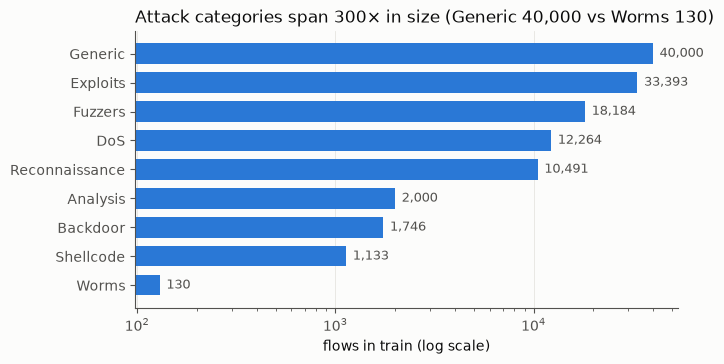

In [7]:
attacks = cats.drop("Normal").sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(attacks.index, attacks.values, color=BLUE, height=0.7)
for y, v in enumerate(attacks.values):
    ax.text(v * 1.08, y, f"{v:,}", va="center", color=MUTED, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("flows in train (log scale)")
ax.set_title("Attack categories span 300× in size (Generic 40,000 vs Worms 130)", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "01_attack_categories.png")
plt.show()

| Category | In networking terms |
|---|---|
| **Generic** | Attacks that work against any block cipher regardless of its structure (e.g. against crypto in protocols) |
| **Exploits** | Using a known software vulnerability (think CVEs against a service) |
| **Fuzzers** | Sending malformed/random input to crash a program or protocol stack |
| **DoS** | Exhausting a host or link so legitimate users can't get service |
| **Reconnaissance** | Scanning and probing: ping sweeps, port scans (what `nmap` does) |
| **Analysis** | Port scans, spam and HTML-file penetration attempts |
| **Backdoor** | Bypassing authentication to get covert remote access |
| **Shellcode** | Small payloads that hand the attacker a shell |
| **Worms** | Self-replicating malware that spreads host to host |

Worms (130 flows) and Shellcode (1,133) are tiny. Phase 7 will struggle with them.
That's a property of the data, not a bug.

## 4. Categorical features: protocol, service, state

These three are text, so the model can't use them until Phase 3 one-hot encodes them.

In [8]:
for col in config.CATEGORICAL:
    unseen = sorted(set(test[col]) - set(train[col]))
    print(f"{col:8s} distinct values: train {train[col].nunique():3d}, test {test[col].nunique():3d}, "
          f"in test but not train: {unseen}")

proto    distinct values: train 133, test 131, in test but not train: []
service  distinct values: train  13, test  13, in test but not train: []
state    distinct values: train   9, test   7, in test but not train: ['ACC', 'CLO']


In [9]:
def attack_rate(df, col, top=10):
    return (df.groupby(col)[config.TARGET]
              .agg(flows="size", attack_rate="mean")
              .sort_values("flows", ascending=False)
              .head(top)
              .style.format({"flows": "{:,}", "attack_rate": "{:.1%}"}))

attack_rate(train, "proto", top=8)

,flows,attack_rate
proto,,
tcp,"79,946",51.1%
udp,"63,283",78.0%
unas,"12,084",100.0%
arp,"2,859",0.0%
ospf,"2,595",97.5%
sctp,"1,150",100.0%
any,300,100.0%
gre,225,100.0%


**`proto`: the IP protocol (Layer 3/4).** `tcp` and `udp` dominate, as you'd expect. There are
**133** distinct values, though. Most are rare IP protocol numbers that only appear in attack
traffic (`unas`, `sctp`, `gre`, `any` are 100% attack here). `arp` is 100% normal: that's ordinary
LAN address resolution. One-hot encoding 133 values is fine for a tree and OK for a neural net.

In [10]:
attack_rate(train, "service", top=13)

,flows,attack_rate
service,,
-,"94,168",61.2%
dns,"47,294",84.2%
http,"18,724",71.4%
smtp,"5,058",68.8%
ftp-data,"3,995",36.1%
ftp,"3,428",64.5%
ssh,"1,302",0.8%
pop3,"1,105",99.6%
dhcp,94,100.0%


**`service`: the application protocol, inferred from the port (Layer 7).** `-` means *no
recognised service*. That's **54% of flows**, and it's a real value, not missing data.
`dns` (UDP/53) has an 84% attack rate: DNS is a common carrier for floods and amplification.
`ssh` is almost entirely normal (0.8% attack): admins logging in.

In [11]:
attack_rate(train, "state", top=9)

,flows,attack_rate
state,,
INT,"82,275",93.1%
FIN,"77,825",52.2%
CON,"13,152",8.0%
REQ,"1,991",53.5%
RST,83,14.5%
ECO,12,0.0%
PAR,1,0.0%
URN,1,0.0%
no,1,0.0%


**`state`: the connection state reported by Argus.** This is where your TCP knowledge pays off:

| State | Meaning | Attack rate |
|---|---|---|
| `FIN` | TCP closed cleanly with FIN/ACK: a **complete** conversation | ~52% |
| `CON` | Connected, data both ways (mostly UDP request + reply) | ~8% |
| `INT` | **Interrupted / no reply**: the destination never answered | ~93% |
| `REQ` | Request sent, still waiting (e.g. half-open handshake) | ~54% |
| `RST` | Reset: the far end refused (TCP RST) | ~14% |

`INT` being 93% attack makes sense: scans and floods fire packets at hosts that never reply.
Normal clients usually get an answer. Two states, `ACC` and `CLO`, appear **only in test**, so
Phase 3's encoder must handle categories it never saw in training (`handle_unknown="ignore"`).

## 5. Volume features: bytes, packets, duration

Attacks and normal traffic have very different shapes:

In [12]:
vol = ["dur", "spkts", "dpkts", "sbytes", "dbytes"]
med = train.groupby(config.TARGET)[vol].median().rename(index={0: "normal", 1: "attack"})
display(med)
print("skewness:", train[vol].skew().round(1).to_dict())

,dur,spkts,dpkts,sbytes,dbytes
label,,,,,
normal,0.038602,12.0,10.0,1470.0,1112.0
attack,0.000009,2.0,0.0,200.0,0.0


skewness: {'dur': 7.5, 'spkts': 40.2, 'dpkts': 36.8, 'sbytes': 45.3, 'dbytes': 39.8}


The **median attack flow is one-directional**: 2 packets out, **0 packets back, 0 bytes back**,
lasting ~9 microseconds. The median normal flow is a real two-way conversation (~12 packets out,
~10 back, ~0.04 s). That's the "fire and forget" pattern of scanning and flooding.

The **skewness** values (40+ for bytes and packets) mean a few huge flows (bulk transfers up to 13 MB)
sit far from the typical few hundred bytes. On a normal axis you'd see one bar and nothing else,
so the plot below uses a log scale. Phase 3 will consider a `log1p` transform before scaling,
which matters a lot for the neural network and very little for the random forest.

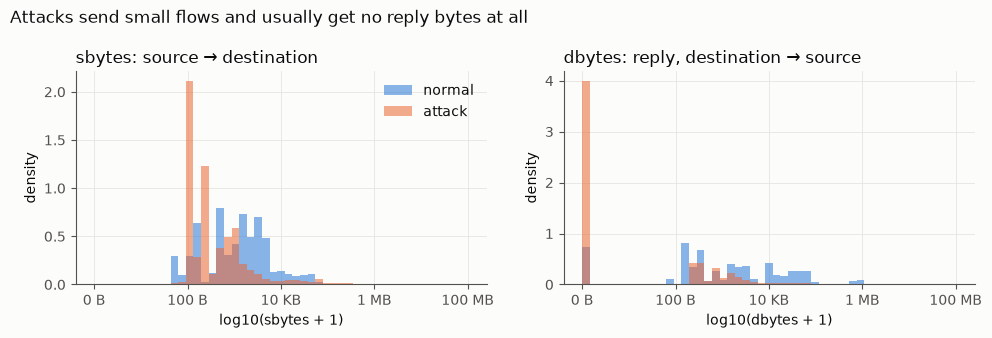

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
bins = np.linspace(0, 8, 50)
for ax, col in zip(axes, ["sbytes", "dbytes"]):
    for lab, color, name in [(0, BLUE, "normal"), (1, ORANGE, "attack")]:
        vals = np.log10(train.loc[train[config.TARGET] == lab, col] + 1)
        ax.hist(vals, bins=bins, color=color, alpha=0.55, label=name, density=True)
    ax.set_xlabel(f"log10({col} + 1)")
    ax.set_xticks(range(0, 9, 2), ["0 B", "100 B", "10 KB", "1 MB", "100 MB"])
    ax.set_ylabel("density")
    ax.set_title(f"{col}: {'source → destination' if col == 'sbytes' else 'reply, destination → source'}", loc="left")
axes[0].legend(frameon=False)
fig.suptitle("Attacks send small flows and usually get no reply bytes at all", x=0.01, ha="left")
fig.tight_layout()
save(fig, "01_bytes_by_label.png")
plt.show()

## 6. ⚠️ The TTL shortcut

**TTL (Time To Live)** is the IP header hop counter you know from CCNA. Each router decrements it,
and the starting value depends on the sender's OS (Linux 64, Windows 128, Cisco 255).

In this lab, attacks came from a few attacker machines and normal traffic from others, so the
**source TTL basically identifies which machine sent the flow**:

In [14]:
ttl = (train.groupby("sttl")[config.TARGET]
            .agg(flows="size", attack_rate="mean")
            .sort_values("flows", ascending=False).head(6))
display(ttl.style.format({"flows": "{:,}", "attack_rate": "{:.1%}"}))

num = train.select_dtypes("number").drop(columns=[config.ID_COL, config.TARGET])
print("Top correlations with the label:")
print(num.corrwith(train[config.TARGET]).abs().sort_values(ascending=False).head(5).round(3))

,flows,attack_rate
sttl,,
254,"114,743",90.2%
31,"39,455",0.0%
62,"17,681",87.7%
0,"3,162",9.6%
64,181,0.0%
1,64,0.0%


Top correlations with the label:
sttl                0.693
ct_state_ttl        0.578
dload               0.394
ct_dst_sport_ltm    0.357
dmean               0.342
dtype: float64


`sttl` is the feature most correlated with the label, and `ct_state_ttl` (built from state + TTL)
is second. TTL 254 → 90% attack, TTL 31 → 0% attack.

**Is this data leakage?** Not strictly: TTL is a genuine header field you'd see in production.
But it's a **shortcut**. The model learns *"which lab machine sent this"* instead of *"does this
look like an attack"*. On a real network, attackers have every possible TTL.

**Decision:** keep TTL features for the main models (to stay comparable with published results),
and in Phase 4 also train **without** `sttl`, `dttl` and `ct_state_ttl` to measure how much the
model leans on them. That kind of ablation is a strong talking point in interviews.

## 7. Duplicates and train/test overlap

In [15]:
features = [c for c in train.columns if c not in (config.ID_COL, config.TARGET, config.ATTACK_CAT)]
dup_train = train.duplicated(subset=features).sum()
print(f"train rows that exactly repeat an earlier row's features: {dup_train:,} ({dup_train/len(train):.1%})")

conflict = train.groupby(features)[config.TARGET].nunique()
print(f"feature patterns labelled BOTH normal and attack: {(conflict > 1).sum():,}")

overlap = test[features].merge(train[features].drop_duplicates(), on=features, how="inner")
print(f"test rows whose exact features also appear in train: {len(overlap):,} ({len(overlap)/len(test):.1%})")

train rows that exactly repeat an earlier row's features: 74,301 (42.4%)


feature patterns labelled BOTH normal and attack: 229


test rows whose exact features also appear in train: 8,541 (10.4%)


- **~42% of training rows are feature-for-feature repeats.** Floods and scans generate thousands
  of identical tiny flows. Duplicates make the model over-weight those patterns.
- Some identical feature rows carry **both labels**. No model can get those all right: it's
  irreducible error.
- **~10% of test rows also appear verbatim in train.** Those are "free" points that slightly inflate
  test scores. It isn't our leak (it's how the official split was made), but we'll mention it in
  the README rather than hide it.

**Decision for Phase 3:** keep the official files untouched for the headline results, and note
the duplication. We will **not** de-duplicate the test set: it's the official benchmark.

## 8. Redundant features

In [16]:
corr = num.corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().sort_values(ascending=False).head(6).round(3))
pairs

is_ftp_login  ct_ftp_cmd    1.000
dbytes        dloss         0.997
sbytes        sloss         0.996
swin          dwin          0.990
ct_srv_src    ct_srv_dst    0.980
dpkts         dloss         0.979
dtype: float64

Some columns are near-copies: `sbytes`/`sloss` (bytes vs retransmitted bytes move together),
`is_ftp_login`/`ct_ftp_cmd`, `swin`/`dwin` (TCP window sizes). Random forests don't care.
For the neural net they're harmless but wasteful. We'll keep them for now and revisit only if needed.

## 9. Takeaways for the next phases

1. **Attack is the majority class** (68% train / 55% test). Accuracy alone is misleading: the
   "always attack" floor is 55% on test. Report precision, recall, F1 and a confusion matrix.
2. **Drop `id` and `attack_cat`** in Phase 3: `id` is a row number, `attack_cat` *is* the label.
3. **One-hot `proto`, `service`, `state`** with unseen categories ignored (`ACC` and `CLO` appear only in test).
4. **Volume features are extremely skewed**: consider `log1p` before scaling for the neural net.
5. **TTL features are a lab shortcut**: run a Phase 4 ablation without them.
6. **Duplicates and 10% train/test overlap** exist in the official split: document them, don't hide them.
7. **Fit every transformation on train only.**

## ✏️ Exercise (yours)

Write `bytes_ratio(df)` that returns `sbytes / (sbytes + dbytes)`: the share of bytes sent by
the source. Then compare its median for normal vs attack.

- Watch for flows where both are 0: division by zero. What should the ratio be then?
- Predict first: will attacks be closer to 0.5 or to 1.0? Why, in TCP terms?

Paste your function into the chat for review.

In [17]:
# Your code here